# AI651 – Deep Learning for Space, Time and Graphs
# Assignment 3

Syed Obaidullah Hassan Chishti - 25280049

### Question 5  Fixed versus Learnable Adjacency Matrices

# Imports

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

seed = 2023
torch.manual_seed(seed)
np.random.seed(seed)

Device: cuda


## Check and download the dataset

In [2]:
import kagglehub

DATA_DIR = kagglehub.dataset_download("liuxu77/largest")
print("Dataset directory:", DATA_DIR)
print("Files:", sorted(os.listdir(DATA_DIR)))

# Sanity check that the files we need are present
for f in ["ca_meta.csv", "ca_rn_adj.npy", "ca_his_raw_2020.h5", "ca_his_raw_2021.h5"]:
    path = os.path.join(DATA_DIR, f)
    print(("OK  " if os.path.exists(path) else "MISSING "), f)

/home/obaid/miniconda3/envs/dl4stg_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset directory: /home/obaid/.cache/kagglehub/datasets/liuxu77/largest/versions/1
Files: ['ca_his_raw_2017.h5', 'ca_his_raw_2018.h5', 'ca_his_raw_2019.h5', 'ca_his_raw_2020.h5', 'ca_his_raw_2021.h5', 'ca_meta.csv', 'ca_rn_adj.npy']
OK   ca_meta.csv
OK   ca_rn_adj.npy
OK   ca_his_raw_2020.h5
OK   ca_his_raw_2021.h5


## Load the San Diego data and build the windows (from Q3 / Q4)

In [3]:
# Metadata -> San Diego (District 11)
ca_meta = pd.read_csv(os.path.join(DATA_DIR, "ca_meta.csv"))
sd_meta = ca_meta[ca_meta.District == 11].reset_index(drop=True)
sd_ids = sd_meta.ID.astype(str).values.tolist()
sd_pos = sd_meta.ID2.values.tolist()
N = len(sd_meta)

# Flow 2020 + 2021, 15-min averages, filled
frames = [pd.read_hdf(os.path.join(DATA_DIR, f"ca_his_raw_{y}.h5"))[sd_ids] for y in ["2020", "2021"]]
flow = pd.concat(frames).sort_index()
flow.index = pd.to_datetime(flow.index)
flow = flow.resample("15min").mean()
# interpolate gaps, fill edges, then zero-out fully-empty sensors (no NaNs left)
flow = flow.interpolate(method="time", limit_direction="both").ffill().bfill().fillna(0.0)

# Aligned adjacency
A_sd = np.load(os.path.join(DATA_DIR, "ca_rn_adj.npy"))[np.ix_(sd_pos, sd_pos)]
print("Sensors:", N, "| flow:", flow.shape, "| adjacency:", A_sd.shape)

Sensors: 716 | flow: (70176, 716) | adjacency: (716, 716)


In [4]:
T_in, T_out = 8, 4
values = flow.values.astype(np.float32)
idx = flow.index

train_vals = values[(idx >= "2020-01-01") & (idx < "2021-01-01")]
val_vals   = values[(idx >= "2021-01-01") & (idx < "2021-04-01")]
test_vals  = values[(idx >= "2021-04-01") & (idx < "2022-01-01")]

mean, std = train_vals.mean(), train_vals.std()      # training statistics only

def make_windows(arr):
    arr = (arr - mean) / std
    X, Y = [], []
    for t in range(len(arr) - T_in - T_out + 1):
        X.append(arr[t:t+T_in]); Y.append(arr[t+T_in:t+T_in+T_out])
    return torch.tensor(np.array(X)[..., None]), torch.tensor(np.array(Y)[..., None])

Xtr, Ytr = make_windows(train_vals)
Xva, Yva = make_windows(val_vals)
Xte, Yte = make_windows(test_vals)
print("Train/val/test windows:", len(Xtr), len(Xva), len(Xte))

Train/val/test windows: 35125 8629 26389


### Two normalizations of the fixed graph

In [5]:
def sym_norm(A):
    A = A + np.eye(A.shape[0])
    deg = A.sum(axis=1)
    d_inv = np.zeros_like(deg)
    nz = deg > 0
    d_inv[nz] = deg[nz] ** -0.5
    D = np.diag(d_inv)
    return D @ A @ D

A_sym = torch.tensor(sym_norm(A_sd), dtype=torch.float32, device=device)

A_rn = torch.tensor(A_sd + np.eye(N), dtype=torch.float32, device=device)
A_rn = A_rn / A_rn.sum(dim=1, keepdim=True).clamp(min=1e-8)   # row-normalized
print("A_sym:", tuple(A_sym.shape), "| A_rn rows sum to 1:",
      torch.allclose(A_rn.sum(1), torch.ones(N, device=device), atol=1e-4))

A_sym: (716, 716) | A_rn rows sum to 1: True


## The model with a swappable graph

In [6]:
class TemporalEncoder(nn.Module):
    def __init__(self, hidden=32, k=3):
        super().__init__()
        self.conv1 = nn.Conv1d(1, hidden, k, padding=k // 2)
        self.conv2 = nn.Conv1d(hidden, hidden, k, padding=k // 2)
        self.relu = nn.ReLU()
    def forward(self, x):
        B, T, N, F = x.shape
        x = x.permute(0, 2, 3, 1).reshape(B * N, F, T)
        z = self.relu(self.conv1(x)); z = self.relu(self.conv2(z))
        return z.mean(dim=-1).reshape(B, N, -1)


class STGNN(nn.Module):
    def __init__(self, hidden=32, horizon=T_out, graph_mode="fixed", d_e=16, topk=None):
        super().__init__()
        self.mode = graph_mode
        self.topk = topk
        self.register_buffer("A_sym", A_sym)
        self.register_buffer("A_rn", A_rn)

        self.temporal = TemporalEncoder(hidden)
        self.Wg = nn.Linear(hidden, hidden, bias=False)
        self.head = nn.Sequential(nn.Linear(hidden, hidden), nn.ReLU(),
                                  nn.Linear(hidden, horizon))
        self.relu = nn.ReLU()

        # Learnable node embeddings for the adaptive graph (Q5b / Q5c)
        if graph_mode in ("adaptive", "hybrid"):
            self.E1 = nn.Parameter(torch.randn(N, d_e) * 0.1)
            self.E2 = nn.Parameter(torch.randn(N, d_e) * 0.1)
        if graph_mode == "hybrid":
            self.raw_alpha = nn.Parameter(torch.tensor(0.0))   # sigmoid(0) = 0.5, learnable

    def adaptive_adj(self):
        scores = self.relu(self.E1 @ self.E2.t())              # (N, N), >= 0
        if self.topk is not None:                              # sparsify BEFORE normalization
            vals, idx = torch.topk(scores, self.topk, dim=1)
            masked = torch.full_like(scores, float("-inf"))
            scores = masked.scatter(1, idx, vals)
        else:
            scores = scores.masked_fill(scores == 0, float("-inf"))
        return torch.softmax(scores, dim=1)                    # row-wise normalize

    def get_adjacency(self):
        if self.mode == "fixed":
            return self.A_sym
        if self.mode == "adaptive":
            return self.adaptive_adj()
        alpha = torch.sigmoid(self.raw_alpha)                  # hybrid, both row-stochastic
        return alpha * self.A_rn + (1 - alpha) * self.adaptive_adj()

    def forward(self, x):
        z = self.temporal(x)
        A = self.get_adjacency()
        h = self.relu(self.Wg(torch.einsum("nm,bmd->bnd", A, z)))
        y = self.head(h)
        return y.permute(0, 2, 1).unsqueeze(-1)

print("params (fixed):   ", sum(p.numel() for p in STGNN(graph_mode="fixed").parameters()))
print("params (adaptive):", sum(p.numel() for p in STGNN(graph_mode="adaptive").parameters()))

params (fixed):    5444
params (adaptive): 28356


### Training and evaluation helpers (shared protocol)

In [7]:
def iterate(X, Y, bs, shuffle):
    n = len(X)
    order = torch.randperm(n) if shuffle else torch.arange(n)
    for s in range(0, n, bs):
        b = order[s:s+bs]
        yield X[b].to(device), Y[b].to(device)

def train_model(model, epochs=10, bs=64, lr=1e-3):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.L1Loss()
    for epoch in range(epochs):
        model.train(); total = 0.0
        for xb, yb in iterate(Xtr, Ytr, bs, True):
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward(); opt.step()
            total += loss.item() * len(xb)
        print(f"epoch {epoch+1:02d}  train MAE(norm) {total/len(Xtr):.4f}")

@torch.no_grad()
def evaluate(model, X, Y, bs=64):
    model.eval(); preds, trues = [], []
    for xb, yb in iterate(X, Y, bs, False):
        preds.append(model(xb).cpu()); trues.append(yb.cpu())
    pred = torch.cat(preds) * std + mean
    true = torch.cat(trues) * std + mean
    mae = (pred - true).abs().mean().item()
    rmse = ((pred - true) ** 2).mean().sqrt().item()
    return mae, rmse

def run_experiment(graph_mode, topk=None, epochs=10):
    model = STGNN(graph_mode=graph_mode, topk=topk)
    t0 = time.perf_counter()
    train_model(model, epochs=epochs)
    train_time = time.perf_counter() - t0
    mae, rmse = evaluate(model, Xte, Yte)
    print(f"[{graph_mode}] test MAE {mae:.3f}  RMSE {rmse:.3f}  time {train_time:.1f}s")
    return model, mae, rmse, train_time

## Q5(a)  Fixed Adjacency

In [8]:
fixed_model, fixed_mae, fixed_rmse, fixed_time = run_experiment("fixed")

epoch 01  train MAE(norm) 0.3522
epoch 02  train MAE(norm) 0.2890
epoch 03  train MAE(norm) 0.2804
epoch 04  train MAE(norm) 0.2723
epoch 05  train MAE(norm) 0.2676
epoch 06  train MAE(norm) 0.2643
epoch 07  train MAE(norm) 0.2616
epoch 08  train MAE(norm) 0.2591
epoch 09  train MAE(norm) 0.2571
epoch 10  train MAE(norm) 0.2547
[fixed] test MAE 49.040  RMSE 80.049  time 86.8s


## Q5(b) - Learnable Adjacency

In [9]:
adaptive_model, adaptive_mae, adaptive_rmse, adaptive_time = run_experiment("adaptive", topk=20)

epoch 01  train MAE(norm) 0.2763
epoch 02  train MAE(norm) 0.1621
epoch 03  train MAE(norm) 0.1507
epoch 04  train MAE(norm) 0.1433
epoch 05  train MAE(norm) 0.1381
epoch 06  train MAE(norm) 0.1356
epoch 07  train MAE(norm) 0.1327
epoch 08  train MAE(norm) 0.1311
epoch 09  train MAE(norm) 0.1294
epoch 10  train MAE(norm) 0.1284
[adaptive] test MAE 28.142  RMSE 45.919  time 92.5s


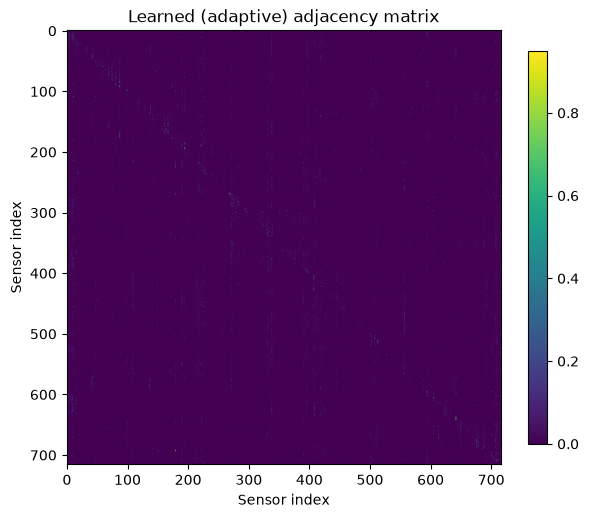

In [10]:
# Visualize the learned adjacency matrix
A_learned = adaptive_model.get_adjacency().detach().cpu().numpy()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(A_learned, cmap="viridis")
ax.set(title="Learned (adaptive) adjacency matrix",
       xlabel="Sensor index", ylabel="Sensor index")
fig.colorbar(im, ax=ax, shrink=0.85)
os.makedirs("figures", exist_ok=True)
fig.savefig("figures/q5b_learned_adjacency.png", dpi=150, bbox_inches="tight")
plt.show()

## Q5(c) - Hybrid Adjacency

In [11]:
hybrid_model, hybrid_mae, hybrid_rmse, hybrid_time = run_experiment("hybrid", topk=20)

learned_alpha = torch.sigmoid(hybrid_model.raw_alpha).item()
print(f"Learned alpha = {learned_alpha:.3f}  "
      f"(weight on the fixed graph; {1-learned_alpha:.3f} on the learned graph)")

epoch 01  train MAE(norm) 0.2607
epoch 02  train MAE(norm) 0.1542
epoch 03  train MAE(norm) 0.1427
epoch 04  train MAE(norm) 0.1364
epoch 05  train MAE(norm) 0.1323
epoch 06  train MAE(norm) 0.1296
epoch 07  train MAE(norm) 0.1277
epoch 08  train MAE(norm) 0.1265
epoch 09  train MAE(norm) 0.1244
epoch 10  train MAE(norm) 0.1233
[hybrid] test MAE 26.144  RMSE 41.379  time 101.8s
Learned alpha = 0.266  (weight on the fixed graph; 0.734 on the learned graph)


## Comparison

In [12]:
results = pd.DataFrame([
    {"Model": "STGNN", "Adjacency": "Fixed",    "MAE": fixed_mae,    "RMSE": fixed_rmse,    "Training time (s)": fixed_time},
    {"Model": "STGNN", "Adjacency": "Adaptive", "MAE": adaptive_mae, "RMSE": adaptive_rmse, "Training time (s)": adaptive_time},
    {"Model": "STGNN", "Adjacency": "Hybrid",   "MAE": hybrid_mae,   "RMSE": hybrid_rmse,   "Training time (s)": hybrid_time},
])
print(results.to_string(index=False))

Model Adjacency       MAE      RMSE  Training time (s)
STGNN     Fixed 49.040112 80.048767          86.835931
STGNN  Adaptive 28.142082 45.918571          92.526779
STGNN    Hybrid 26.143724 41.378693         101.825667
